# Exploratory Data Analysis - UCI Heart Disease (Cleveland)

This notebook explores the raw and cleaned Cleveland heart-disease dataset produced by
`src/ingest.py` and `src/clean.py`, ahead of feature engineering and model training
(`src/features.py`, `src/train.py`).

Sections:
1. Load raw + cleaned data
2. Missing values
3. Class balance
4. Numeric feature distributions
5. Correlation heatmap
6. Categorical features vs. target
7. Takeaways that motivated the feature-engineering choices in `src/features.py`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import CONTINUOUS_FEATURES, NOMINAL_FEATURES, RAW_DATA_FILE, CLEAN_DATA_FILE, TARGET  # noqa: E402

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

raw_df = pd.read_csv(RAW_DATA_FILE)
clean_df = pd.read_csv(CLEAN_DATA_FILE)
print(f"raw: {raw_df.shape}, clean: {clean_df.shape}")
clean_df.head()

raw: (303, 14), clean: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


## 1. Missing values

The UCI export encodes missing values as `?`, parsed to `NaN` by `src/ingest.py`. Only `ca`
and `thal` are affected, and only in a handful of rows.

ca      4
thal    2
dtype: int64


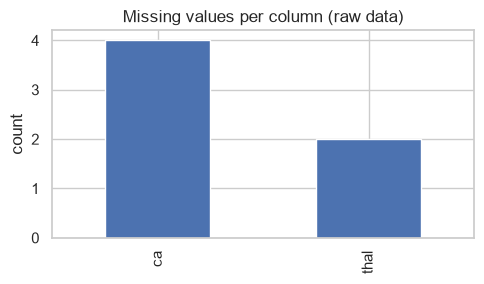

In [2]:
missing = raw_df.isna().sum()
missing = missing[missing > 0]
print(missing)
missing.plot(kind="bar", title="Missing values per column (raw data)", ylabel="count", figsize=(5, 3))
plt.tight_layout()
plt.show()

## 2. Class balance

The target is binarised from the 5-level `num` severity column: `0` = no disease, `1` = any
observed disease (`num > 0`).

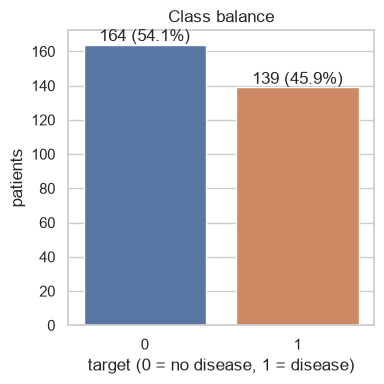

In [3]:
counts = clean_df[TARGET].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, hue=counts.index.astype(str),
            palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for i, (count, p) in enumerate(zip(counts.values, pct.values, strict=True)):
    ax.text(i, count + 2, f"{count} ({p}%)", ha="center")
ax.set_xlabel("target (0 = no disease, 1 = disease)")
ax.set_ylabel("patients")
ax.set_title("Class balance")
plt.tight_layout()
plt.show()

## 3. Numeric feature distributions

Continuous/ordinal features (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`), split by
target, with summary statistics.

In [4]:
clean_df[CONTINUOUS_FEATURES].describe().round(2)

,age,trestbps,chol,thalach,oldpeak,ca
count,303.00,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04,0.66
std,9.04,17.60,51.78,22.88,1.16,0.93
min,29.00,94.00,126.00,71.00,0.00,0.00
25%,48.00,120.00,211.00,133.50,0.00,0.00
50%,56.00,130.00,241.00,153.00,0.80,0.00
75%,61.00,140.00,275.00,166.00,1.60,1.00
max,77.00,200.00,564.00,202.00,6.20,3.00


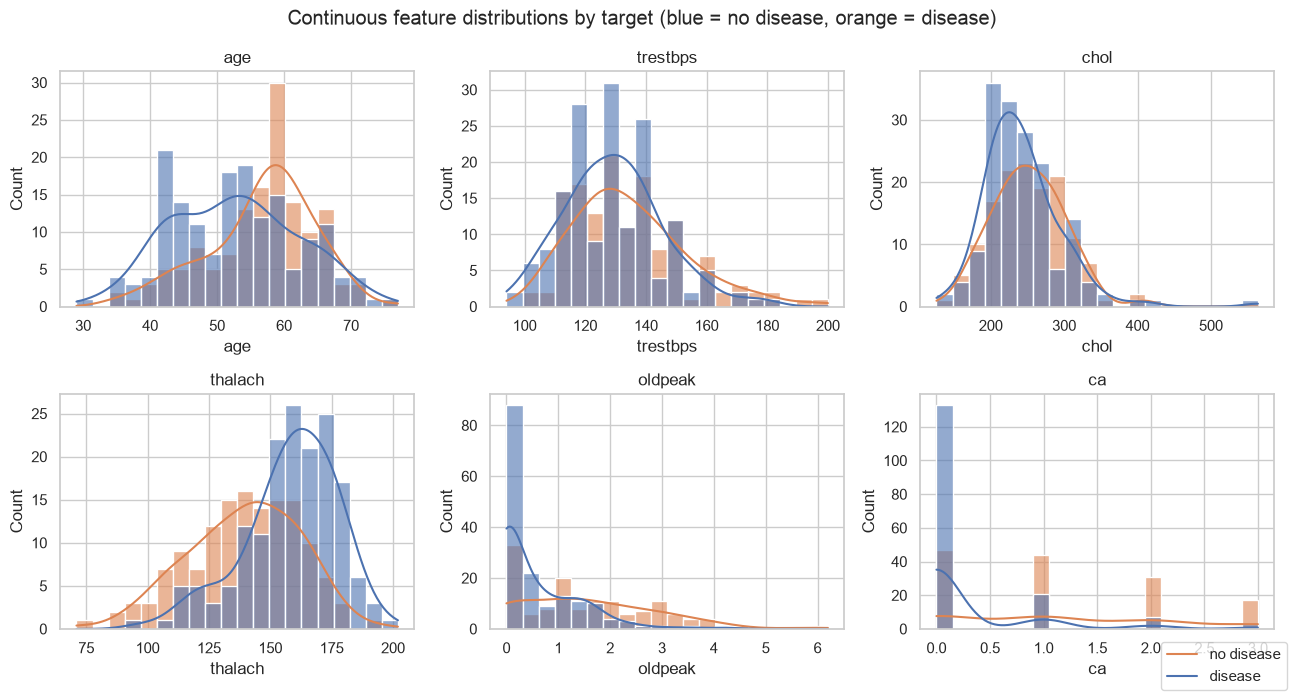

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), CONTINUOUS_FEATURES, strict=False):
    sns.histplot(data=clean_df, x=col, hue=TARGET, kde=True, bins=20, ax=ax,
                 palette=["#4C72B0", "#DD8452"], alpha=0.6, legend=False)
    ax.set_title(col)
fig.suptitle("Continuous feature distributions by target (blue = no disease, orange = disease)")
fig.legend(labels=["no disease", "disease"], loc="lower right")
plt.tight_layout()
plt.show()

## 4. Correlation heatmap

All 13 features plus the target, Pearson correlation. This is mostly a sanity check for
redundant features (none are strongly collinear enough to drop) and to see which raw signals
correlate most with the target before any encoding.

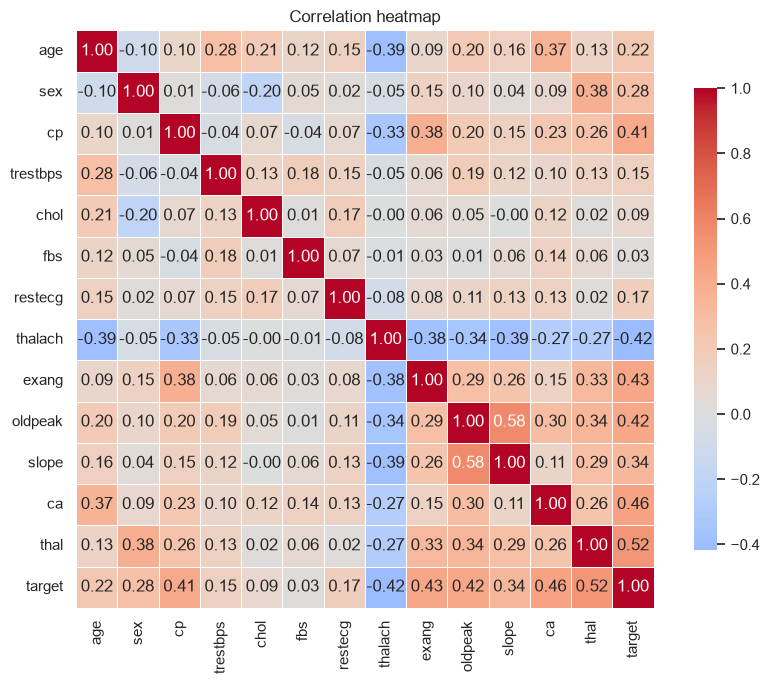

Features most correlated with target:
thal        0.522
ca          0.460
exang       0.432
oldpeak     0.425
thalach     0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64


In [6]:
corr = clean_df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.show()

print("Features most correlated with target:")
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).round(3))

## 5. Categorical features vs. target

The four nominal features one-hot encoded in `src/features.py`: chest pain type (`cp`),
resting ECG (`restecg`), ST slope (`slope`) and thalassemia (`thal`).

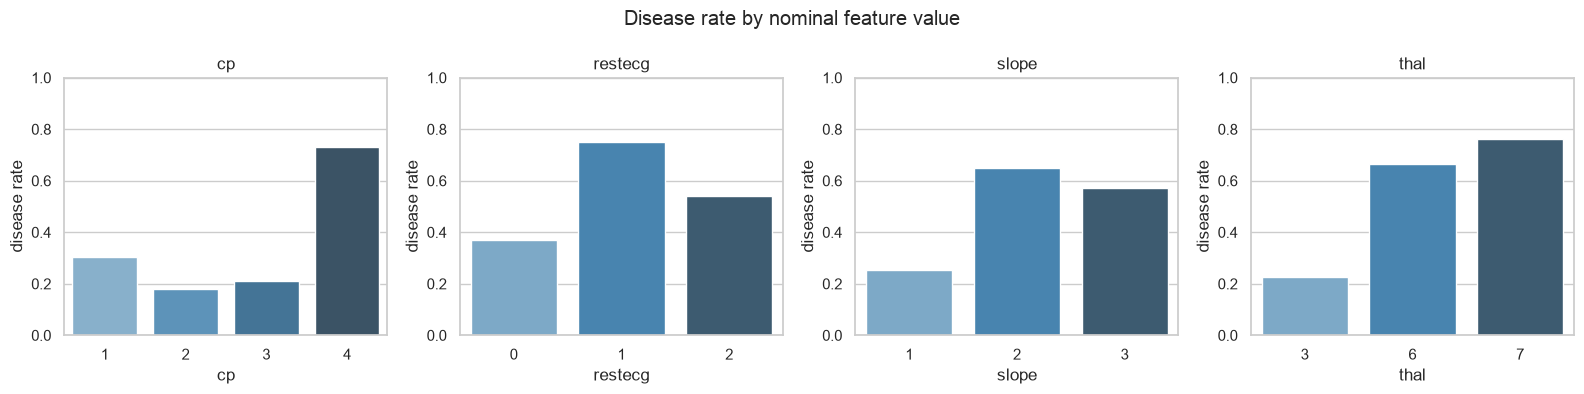

In [7]:
fig, axes = plt.subplots(1, len(NOMINAL_FEATURES), figsize=(16, 4))
for ax, col in zip(axes, NOMINAL_FEATURES, strict=True):
    rate = clean_df.groupby(col)[TARGET].mean().sort_index()
    sns.barplot(x=rate.index.astype(str), y=rate.values, hue=rate.index.astype(str),
                palette="Blues_d", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("disease rate")
    ax.set_ylim(0, 1)
fig.suptitle("Disease rate by nominal feature value")
plt.tight_layout()
plt.show()

## 6. Takeaways -> feature engineering decisions

- **Missing data is minor and localised** (`ca`: 4 rows, `thal`: 2 rows out of 303) - mode
  imputation in `src/clean.py` is sufficient; no rows need to be dropped.
- **Classes are reasonably balanced** (54.1% / 45.9%), so plain accuracy is still meaningful,
  but `src/train.py` also tracks precision/recall/F1/ROC-AUC and tries `class_weight="balanced"`
  during tuning in case that changes.
- **`thal`, `ca`, `exang`, `oldpeak`, `thalach` and `cp` correlate most with the target.** None of
  the pairwise correlations are high enough (> 0.6) to justify dropping a feature for redundancy.
- **`cp`, `restecg`, `slope` and `thal` are not ordinal** - e.g. `cp=4` has a much higher disease
  rate than `cp=1-3`, which aren't monotonically increasing. Label/ordinal-encoding these would
  impose a false ordering, so `src/features.py` one-hot encodes them (`NOMINAL_FEATURES`).
- **`ca` (vessels coloured, 0-4) behaves like a count/ordinal measure** - the disease rate rises
  roughly monotonically with more vessels coloured, so it is scaled as numeric rather than
  one-hot encoded (`CONTINUOUS_FEATURES` in `src/config.py`), unlike the reference project style
  of one-hot-encoding every non-numeric-looking column.
- **`sex`, `fbs`, `exang` are already binary** - no encoding needed, just imputation
  (`BINARY_FEATURES`).

These observations map directly onto the three-way column split in `src/config.py` /
`src/features.py` used by both training and the serving API.